In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# 1. Define 18 Nifty 50 Stocks across 6 Sectors + Benchmark
stock_sectors = {
    'HDFCBANK.NS': 'Banking & Finance',
    'ICICIBANK.NS': 'Banking & Finance',
    'SBIN.NS': 'Banking & Finance',
    'TCS.NS': 'IT Services',
    'INFY.NS': 'IT Services',
    'HCLTECH.NS': 'IT Services',
    'RELIANCE.NS': 'Energy & Infra',
    'NTPC.NS': 'Energy & Infra',
    'LT.NS': 'Energy & Infra',
    'ITC.NS': 'FMCG',
    'HINDUNILVR.NS': 'FMCG',
    'NESTLEIND.NS': 'FMCG',
    'M&M.NS': 'Auto',
    'MARUTI.NS': 'Auto',
    'BAJAJ-AUTO.NS': 'Auto',
    'SUNPHARMA.NS': 'Pharma & Telecom',
    'CIPLA.NS': 'Pharma & Telecom',
    'BHARTIARTL.NS': 'Pharma & Telecom'
}

tickers = list(stock_sectors.keys()) + ['^NSEI']

# 2. Download 5 Years of Daily Data (Nov 2021 - Nov 2026)
start_date = '2021-11-19'
end_date = '2026-11-19'

print("Downloading NSE data...")
raw_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)['Close']

# 3. Clean & Align Dates
# Drop days where the NSE market was closed (all NaNs) and forward-fill any single-day gaps
prices = raw_data.dropna(how='all').ffill().dropna()
print(f"Clean dataset shape: {prices.shape[0]} trading days x {prices.shape[1]} tickers")

# 4. Calculate Daily Returns & Financial Metrics
returns = prices.pct_change().dropna()
risk_free_rate = 0.0727  # Current India 10Y G-Sec yield (7.27%)
trading_days = 252

market_returns = returns['^NSEI']
market_var = market_returns.var()

metrics_list = []

for ticker in tickers:
    # Annualized Return (CAGR)
    total_days = len(prices)
    cagr = (prices[ticker].iloc[-1] / prices[ticker].iloc[0]) ** (trading_days / total_days) - 1

    # Annualized Volatility
    ann_vol = returns[ticker].std() * np.sqrt(trading_days)

    # Sharpe Ratio
    sharpe = (cagr - risk_free_rate) / ann_vol

    # Beta against Nifty 50
    cov_with_market = returns[ticker].cov(market_returns)
    beta = cov_with_market / market_var

    # Maximum Drawdown
    cum_returns = (1 + returns[ticker]).cumprod()
    running_max = cum_returns.cummax()
    drawdown = (cum_returns - running_max) / running_max
    max_dd = drawdown.min()

    # 95% Historical Daily Value at Risk (VaR)
    var_95 = np.percentile(returns[ticker], 5)

    metrics_list.append({
        'Ticker': ticker.replace('.NS', ''),
        'Sector': stock_sectors.get(ticker, 'Benchmark Index'),
        'Annualized_Return_Pct': round(cagr * 100, 2),
        'Annualized_Volatility_Pct': round(ann_vol * 100, 2),
        'Sharpe_Ratio': round(sharpe, 2),
        'Beta': round(beta, 2),
        'Max_Drawdown_Pct': round(max_dd * 100, 2),
        'Daily_VaR_95_Pct': round(var_95 * 100, 2)
    })

metrics_df = pd.DataFrame(metrics_list).sort_values(by='Sharpe_Ratio', ascending=False)
print("\n--- RISK-RETURN SUMMARY TABLE ---")
print(metrics_df.to_string(index=False))

# 5. Export Clean CSVs for MySQL & Power BI
# Normalized long format for SQL fact_daily_prices table
prices_long = prices.reset_index().melt(id_vars='Date', var_name='Ticker', value_name='Close_Price')
prices_long['Ticker'] = prices_long['Ticker'].str.replace('.NS', '', regex=False)
prices_long['Daily_Return'] = prices_long.groupby('Ticker')['Close_Price'].pct_change().fillna(0)

# Dimension table for SQL dim_stocks
dim_stocks = pd.DataFrame([
    {'Ticker': k.replace('.NS', ''), 'Sector': v, 'Is_Benchmark': 0} for k, v in stock_sectors.items()
] + [{'Ticker': '^NSEI', 'Sector': 'Benchmark Index', 'Is_Benchmark': 1}])

# Correlation matrix for Power BI / Heatmap
corr_matrix = returns[list(stock_sectors.keys())].corr()
corr_matrix.columns = [c.replace('.NS', '') for c in corr_matrix.columns]
corr_matrix.index = [i.replace('.NS', '') for i in corr_matrix.index]

prices_long.to_csv('fact_daily_prices.csv', index=False)
dim_stocks.to_csv('dim_stocks.csv', index=False)
metrics_df.to_csv('stock_risk_metrics.csv', index=False)
corr_matrix.to_csv('correlation_matrix.csv')

print("\nCSVs exported successfully: fact_daily_prices.csv, dim_stocks.csv, stock_risk_metrics.csv, correlation_matrix.csv")

[*********************100%***********************]  19 of 19 completed


Clean dataset shape: 1235 trading days x 19 tickers

--- RISK-RETURN SUMMARY TABLE ---
    Ticker            Sector  Annualized_Return_Pct  Annualized_Volatility_Pct  Sharpe_Ratio  Beta  Max_Drawdown_Pct  Daily_VaR_95_Pct
       M&M              Auto                  32.05                      28.02          0.88  1.22            -26.89             -2.74
BAJAJ-AUTO              Auto                  28.67                      24.50          0.87  0.79            -42.31             -2.21
BHARTIARTL  Pharma & Telecom                  24.93                      21.44          0.82  0.80            -18.77             -1.96
 SUNPHARMA  Pharma & Telecom                  21.06                      19.82          0.70  0.55            -19.13             -1.97
      NTPC    Energy & Infra                  24.55                      24.65          0.70  0.89            -32.30             -2.14
      SBIN Banking & Finance                  21.06                      24.41          0.56  1.15     

In [ ]:
from scipy.optimize import minimize

# Filter out benchmark index for stock-only optimization
stock_tickers = [t for t in tickers if t != '^NSEI']
stock_returns = returns[stock_tickers]

# Split into In-Sample (First ~4 years) and Out-of-Sample (Last 252 trading days / Year 5)
split_idx = len(stock_returns) - 252
train_returns = stock_returns.iloc[:split_idx]
test_returns = stock_returns.iloc[split_idx:]
test_benchmark = returns['^NSEI'].iloc[split_idx:]

mean_daily_returns = train_returns.mean()
cov_matrix = train_returns.cov()
num_assets = len(stock_tickers)

# Helper functions for annualized return, volatility, and negative Sharpe
def portfolio_performance(weights, mean_ret, cov_mat):
    ret = np.sum(mean_ret * weights) * 252
    vol = np.sqrt(np.dot(weights.T, np.dot(cov_mat * 252, weights)))
    return ret, vol

def neg_sharpe(weights, mean_ret, cov_mat, rf):
    ret, vol = portfolio_performance(weights, mean_ret, cov_mat)
    return -(ret - rf) / vol

def portfolio_vol(weights, mean_ret, cov_mat):
    return portfolio_performance(weights, mean_ret, cov_mat)[1]

# Constraints & Bounds (Weights sum to 1; max 15% per stock to prevent concentration)
constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0.0, 0.15) for _ in range(num_assets))
init_guess = num_assets * [1. / num_assets]

# 1. Optimize Maximum Sharpe Ratio Portfolio
opt_sharpe = minimize(neg_sharpe, init_guess, args=(mean_daily_returns, cov_matrix, risk_free_rate),
                      method='SLSQP', bounds=bounds, constraints=constraints)
max_sharpe_weights = opt_sharpe.x

# 2. Optimize Minimum Volatility Portfolio
opt_min_vol = minimize(portfolio_vol, init_guess, args=(mean_daily_returns, cov_matrix),
                       method='SLSQP', bounds=bounds, constraints=constraints)
min_vol_weights = opt_min_vol.x

# 3. Simulate 5,000 Random Portfolios for Efficient Frontier
np.random.seed(42)
ef_results = []
for _ in range(5000):
    w = np.random.random(num_assets)
    w /= np.sum(w)
    r, v = portfolio_performance(w, mean_daily_returns, cov_matrix)
    s = (r - risk_free_rate) / v
    ef_results.append({'Volatility_Pct': round(v*100, 2), 'Return_Pct': round(r*100, 2), 'Sharpe': round(s, 2)})

ef_df = pd.DataFrame(ef_results)

# 4. Save Optimal Weights Table
weights_df = pd.DataFrame({
    'Ticker': [t.replace('.NS', '') for t in stock_tickers],
    'Sector': [stock_sectors[t] for t in stock_tickers],
    'Max_Sharpe_Weight_Pct': np.round(max_sharpe_weights * 100, 2),
    'Min_Vol_Weight_Pct': np.round(min_vol_weights * 100, 2),
    'Equal_Weight_Pct': round(100 / num_assets, 2)
}).sort_values(by='Max_Sharpe_Weight_Pct', ascending=False)

print("--- OPTIMAL PORTFOLIO ALLOCATIONS (%) ---")
print(weights_df.to_string(index=False))

# 5. Out-of-Sample Backtest (Year 5: Last 252 Trading Days)
equal_weights = np.array([1. / num_assets] * num_assets)

backtest_df = pd.DataFrame(index=test_returns.index)
backtest_df['Max_Sharpe_Portfolio'] = (1 + test_returns.dot(max_sharpe_weights)).cumprod() * 100
backtest_df['Min_Vol_Portfolio'] = (1 + test_returns.dot(min_vol_weights)).cumprod() * 100
backtest_df['Equal_Weight_Portfolio'] = (1 + test_returns.dot(equal_weights)).cumprod() * 100
backtest_df['Nifty_50_Benchmark'] = (1 + test_benchmark).cumprod() * 100
backtest_df = backtest_df.reset_index()

print("\n--- YEAR 5 OUT-OF-SAMPLE BACKTEST (Base = 100) ---")
print(backtest_df.tail(1).to_string(index=False))

weights_df.to_csv('optimal_weights.csv', index=False)
backtest_df.to_csv('backtest_cumulative_returns.csv', index=False)
ef_df.to_csv('efficient_frontier.csv', index=False)
print("\nExported: optimal_weights.csv, backtest_cumulative_returns.csv, efficient_frontier.csv")

--- OPTIMAL PORTFOLIO ALLOCATIONS (%) ---
    Ticker            Sector  Max_Sharpe_Weight_Pct  Min_Vol_Weight_Pct  Equal_Weight_Pct
      NTPC    Energy & Infra                  15.00                3.58              5.56
       ITC              FMCG                  15.00               13.46              5.56
BAJAJ-AUTO              Auto                  15.00                3.15              5.56
 SUNPHARMA  Pharma & Telecom                  15.00               10.94              5.56
BHARTIARTL  Pharma & Telecom                  15.00                5.31              5.56
       M&M              Auto                  15.00                0.00              5.56
     CIPLA  Pharma & Telecom                   6.44               11.28              5.56
        LT    Energy & Infra                   2.60                0.00              5.56
 ICICIBANK Banking & Finance                   0.59                8.02              5.56
    MARUTI              Auto                   0.37       

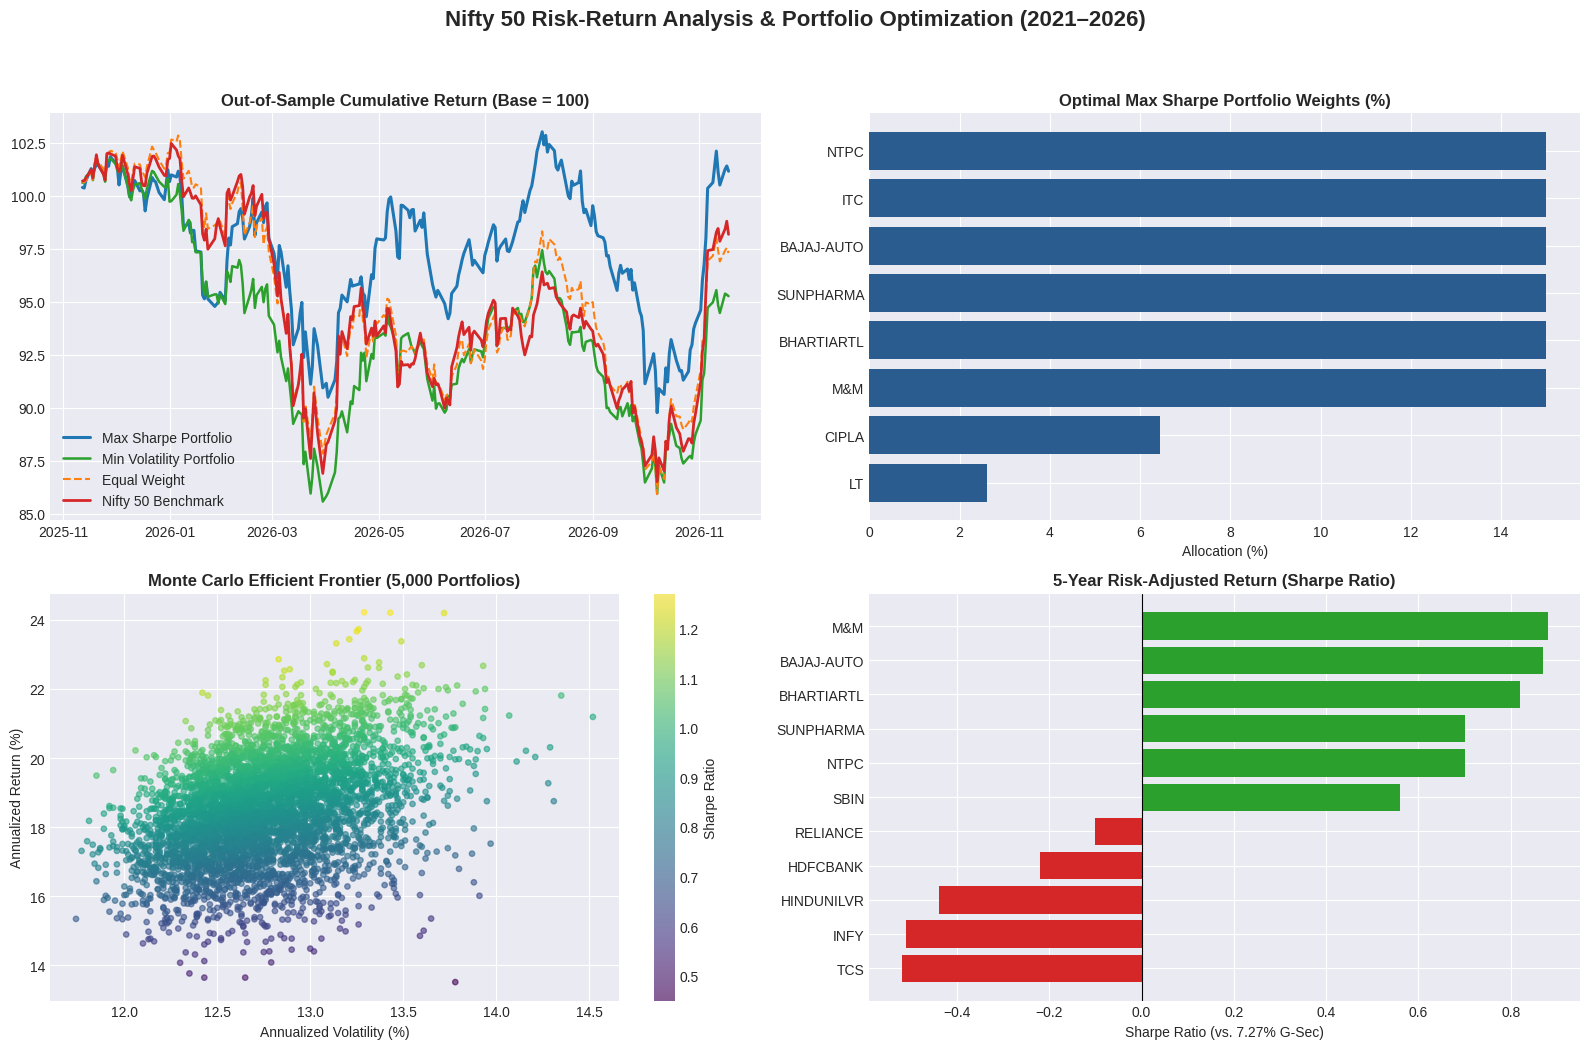

In [ ]:
nimport matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Nifty 50 Risk-Return Analysis & Portfolio Optimization (2021–2026)', fontsize=16, fontweight='bold')

# 1. Top-Left: Year 5 Out-of-Sample Cumulative Growth
axes[0, 0].plot(backtest_df['Date'], backtest_df['Max_Sharpe_Portfolio'], label='Max Sharpe Portfolio', linewidth=2.2, color='#1f77b4')
axes[0, 0].plot(backtest_df['Date'], backtest_df['Min_Vol_Portfolio'], label='Min Volatility Portfolio', linewidth=1.8, color='#2ca02c')
axes[0, 0].plot(backtest_df['Date'], backtest_df['Equal_Weight_Portfolio'], label='Equal Weight', linewidth=1.5, linestyle='--', color='#ff7f0e')
axes[0, 0].plot(backtest_df['Date'], backtest_df['Nifty_50_Benchmark'], label='Nifty 50 Benchmark', linewidth=2, color='#d62728')
axes[0, 0].set_title('Out-of-Sample Cumulative Return (Base = 100)', fontweight='bold')
axes[0, 0].legend()

# 2. Top-Right: Optimal Max Sharpe Allocation (>1%)
active_weights = weights_df[weights_df['Max_Sharpe_Weight_Pct'] > 1.0]
axes[0, 1].barh(active_weights['Ticker'], active_weights['Max_Sharpe_Weight_Pct'], color='#2b5c8f')
axes[0, 1].invert_yaxis()
axes[0, 1].set_title('Optimal Max Sharpe Portfolio Weights (%)', fontweight='bold')
axes[0, 1].set_xlabel('Allocation (%)')

# 3. Bottom-Left: Efficient Frontier Simulation
sc = axes[1, 0].scatter(ef_df['Volatility_Pct'], ef_df['Return_Pct'], c=ef_df['Sharpe'], cmap='viridis', alpha=0.6, s=15)
plt.colorbar(sc, ax=axes[1, 0], label='Sharpe Ratio')
axes[1, 0].set_title('Monte Carlo Efficient Frontier (5,000 Portfolios)', fontweight='bold')
axes[1, 0].set_xlabel('Annualized Volatility (%)')
axes[1, 0].set_ylabel('Annualized Return (%)')

# 4. Bottom-Right: Top & Bottom Stocks by Sharpe Ratio
top_bottom = pd.concat([metrics_df.head(6), metrics_df.tail(5)])
colors = ['#2ca02c' if x > 0 else '#d62728' for x in top_bottom['Sharpe_Ratio']]
axes[1, 1].barh(top_bottom['Ticker'], top_bottom['Sharpe_Ratio'], color=colors)
axes[1, 1].invert_yaxis()
axes[1, 1].axvline(0, color='black', linewidth=0.8)
axes[1, 1].set_title('5-Year Risk-Adjusted Return (Sharpe Ratio)', fontweight='bold')
axes[1, 1].set_xlabel('Sharpe Ratio (vs. 7.27% G-Sec)')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('nifty50_dashboard.png', dpi=300)
plt.show()